# A2 02 Phân tích dữ liệu hành khách Titanic

**Lương Công Hoàng Duy — 240464 (60%). Lê Nguyễn Gia Bảo — 240233 (40%).**

## Khai báo công cụ AI
OpenAI Codex hỗ trợ cấu trúc mã, soạn diễn giải và đối chiếu số liệu. Python, Pandas, NumPy, Matplotlib và Seaborn thực hiện phân tích. AI không phải nguồn dữ liệu hành khách.

## Cách kiểm chứng
Chạy từ đầu đến cuối trong kernel mới; kiểm tra SHA256, shape, miền giá trị, mẫu số và tổng số sống bằng assert; đối chiếu số sống / tổng số trong từng nhóm. Việc kiểm tra kỹ thuật không thay thế trách nhiệm hai thành viên tự chạy lại và giải thích từng dòng mã.

**Tầng Cơ bản**, theo đề A2-02. Chỉ dùng `train.csv` 891 dòng có Survived. Không ghép test.csv, không nhân bản dòng hoặc tạo ngày giả. Bài A2 không huấn luyện mô hình học máy.

## 1. Bài toán và ba câu hỏi chính thức

Giảng viên và sinh viên dùng kết quả để hiểu cách làm sạch dữ liệu, so sánh nhóm và phân biệt liên hệ với nguyên nhân.

1. **Những yếu tố nào liên quan tới khả năng sống sót?**
2. **Giả thuyết “phụ nữ và trẻ em trước” có được phản ánh trong dữ liệu không?**
3. **Hạng vé có ảnh hưởng độc lập với giới tính không, hay chỉ là biến trung gian?**

Câu 1 khảo sát giới tính, tuổi, hạng vé và gia đình. Câu 2 quy ước trẻ em là tuổi ≤12; nhóm >12 còn gồm thiếu niên. Câu 3 bắt buộc dùng bảng chéo giới tính × hạng vé. Phân tầng mô tả không đủ xác định tác động nhân quả độc lập hoặc cơ chế trung gian.

## 2. Nguồn và ý nghĩa dữ liệu

Nguồn bộ dữ liệu: [Kaggle Titanic](https://www.kaggle.com/competitions/titanic/data). Kaggle mô tả train.csv có 891 hành khách và nhãn Survived. Bài dùng bản CSV đã có trên máy, đặt tên `train.csv`; SHA256 **4a437fde05fe5264e1701a7387ac6fb75393772ba38bb2c9c566405af5af4bd7**. Không khai báo đã tải trực tiếp từ Kaggle trong lần thực hiện này.

Điều kiện sử dụng: theo [quy tắc cuộc thi Kaggle](https://www.kaggle.com/competitions/titanic/rules). Không tự gán CC0 hoặc khẳng định quyền tái phân phối. Repo có thể dùng link nguồn thay dữ liệu gốc. Các bảng/biểu đồ chỉ xuất dữ liệu tổng hợp.

12 trường: PassengerId (mã hồ sơ), Survived (1 sống/0 không sống), Pclass (hạng 1/2/3), Name (tên), Sex (giới tính trong nguồn), Age (tuổi năm), SibSp (anh chị em/vợ chồng đi cùng), Parch (cha mẹ/con đi cùng), Ticket (mã vé), Fare (giá vé ghi trong nguồn), Cabin (cabin), Embarked (cảng C/Q/S). Không có ngày tháng; không coi đây là toàn bộ hành khách hoặc thủy thủ đoàn.

In [1]:
from pathlib import Path
import hashlib
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display

DATA_FILE = Path('train.csv')
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
if not DATA_FILE.exists():
    raise FileNotFoundError('Đặt train.csv cùng notebook. Trên Colab: tải CSV lên Files trước khi Run all.')
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 110})

def summary(frame, keys):
    """Số người, số sống, tỷ lệ theo nhóm; không bỏ nhóm thiếu âm thầm."""
    r = frame.groupby(keys, observed=True, dropna=False)['survived'].agg(n='count', alive='sum', rate='mean')
    return r.assign(pct=100*r['rate']).reset_index()

def finish(fig, ax, title, filename):
    ax.set_title(textwrap.fill(title, 76), loc='left', fontweight='bold', pad=14)
    fig.tight_layout()
    fig.savefig(FIGURES/filename, dpi=180, bbox_inches='tight')
    plt.show()

def rate_bars(frame, key, label_map, xlabel, title, filename):
    s = summary(frame, key)
    display(s)
    fig, ax = plt.subplots()
    bars = ax.bar(np.arange(len(s)), s['rate'], width=.58, color='#087F86')
    ax.set_xticks(np.arange(len(s)), [label_map.get(v, str(v)) for v in s[key]])
    ax.set(xlabel=xlabel, ylabel='Tỷ lệ sống (%)', ylim=(0, 1.10))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    for bar, row in zip(bars, s.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.025,
                f'{row.pct:.1f}%\n{row.alive}/{row.n}', ha='center', fontsize=10)
    finish(fig, ax, title, filename)
    return s

## 3. Khảo sát ban đầu
`shape` kiểm tra kích thước, `info` xem kiểu dữ liệu và số có mặt, `describe` tóm tắt phân phối, `isna().sum()` định lượng dữ liệu thiếu. Không hiển thị tên/mã vé hành khách trong đầu ra minh họa.

In [2]:
raw = pd.read_csv(DATA_FILE, na_values=['?', ''])
print('Shape:', raw.shape)
print('SHA256:', hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())
raw.info()
display(raw.drop(columns=['Name', 'Ticket', 'Cabin']).head())
display(raw.describe().T)
display(raw.isna().sum().rename('Số thiếu').to_frame().assign(Phan_tram=100*raw.isna().mean()))

Shape: (891, 12)
SHA256: 4a437fde05fe5264e1701a7387ac6fb75393772ba38bb2c9c566405af5af4bd7
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.0,1,0,7.2500,S
1,2,1,1,female,38.0,1,0,71.2833,C
2,3,1,3,female,26.0,0,0,7.9250,S
3,4,1,1,female,35.0,1,0,53.1000,S
4,5,0,3,male,35.0,0,0,8.0500,S


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,Số thiếu,Phan_tram
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


Nhận xét: dữ liệu có 891 dòng và 12 cột. Age thiếu 177/891 (19,9%), Cabin thiếu 687/891 (77,1%), Embarked thiếu 2/891 (0,2%). Fare không thiếu; số 0 không đồng nghĩa với thiếu. Age có số lẻ ở trẻ nhỏ, nên không ép về số nguyên. Survived là biến nhị phân; trung bình của nó chính là tỷ lệ sống trên mẫu số có kết quả.

## 4. Làm sạch và nhật ký
Giữ nguyên CSV. Bảng phân tích dùng tên cột chữ thường để viết mã nhất quán. Bỏ các trường định danh không cần và Cabin khỏi bảng phân tích. Giữ tuổi thiếu trong bảng chính, chỉ dùng tuổi có mặt cho câu hỏi về tuổi. Không điền người thân thiếu thành 0. Giá vé cao được gắn cờ IQR để khảo sát, không tự xóa khi chưa có bằng chứng sai.

In [3]:
duplicates = int(raw.duplicated().sum())
clean = raw.drop_duplicates().rename(columns=str.lower).copy()
coercions = {}
for col in ['passengerid', 'survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']:
    before = int(clean[col].isna().sum())
    clean[col] = pd.to_numeric(clean[col], errors='coerce')
    coercions[col] = int(clean[col].isna().sum()) - before
category_changes = {}
for col in ['sex', 'embarked']:
    before = clean[col].astype('string')
    after = before.str.strip().str.lower()
    category_changes[col] = int((before != after).fillna(False).sum())
    clean[col] = after
assert clean[['sibsp', 'parch']].notna().all().all()
clean['family_size'] = clean['sibsp'] + clean['parch'] + 1
clean['age_group'] = pd.cut(clean['age'], [0, 12, 18, 35, 60, np.inf],
    labels=['0–12', '>12–18', '>18–35', '>35–60', '>60'], include_lowest=True)
df = clean[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'family_size', 'age_group']].copy()
q1, q3 = df['fare'].quantile([.25, .75])
fare_upper = q3 + 1.5*(q3-q1)
fare_flags = int((df['fare'] > fare_upper).sum())
log = pd.DataFrame([
    ['Chuẩn hóa ký hiệu thiếu', 'Đọc ô rỗng/? thành NaN', 891, 891, 'Age 177; Cabin 687; Embarked 2'],
    ['Bỏ dòng trùng hoàn toàn', 'Tránh đếm lặp hồ sơ', 891, len(clean), f'{duplicates} dòng xóa'],
    ['Ép kiểu số', 'Tính toán đúng kiểu, ghi số lỗi', len(clean), len(clean), f'{sum(coercions.values())} ô mới thành NaN'],
    ['Chuẩn hóa nhãn', 'Strip, lowercase để nhóm thống nhất', len(clean), len(clean), str(category_changes)],
    ['Kiểm tra miền giá trị', 'Không âm tuổi, giá vé, số thân nhân', len(clean), len(clean), 'Kiểm tra bằng assert ở cuối'],
    ['Khảo sát giá vé cao', 'Gắn cờ IQR, chưa đủ bằng chứng sai', len(clean), len(clean), f'{fare_flags} dòng > {fare_upper:.4f}; giữ nguyên'],
    ['Giữ tuổi thiếu', 'Không tạo tuổi giả trong phân tích chính', len(clean), len(df), '177 thiếu; 714 hồ sơ vào phân tích tuổi'],
    ['Giữ Embarked thiếu', 'Không phân tích cảng trong 3 câu hỏi', len(df), len(df), '2 thiếu, không làm mất hành khách'],
    ['Bỏ 4 trường, thêm 2 biến', 'Bỏ passengerid/name/ticket/cabin; thêm family_size/age_group', len(clean), len(df), '10 cột; Cabin thiếu 77,1%; CSV giữ nguyên'],
], columns=['Thao tác', 'Lý do', 'Dòng trước', 'Dòng sau', 'Ảnh hưởng'])
display(log)
print('Bảng phân tích:', df.shape, '; fare = 0:', int(df.fare.eq(0).sum()))
display(df.isna().sum().rename('Số thiếu sau làm sạch').to_frame())

,Thao tác,Lý do,Dòng trước,Dòng sau,Ảnh hưởng
0,Chuẩn hóa ký hiệu thiếu,Đọc ô rỗng/? thành NaN,891,891,Age 177; Cabin 687; Embarked 2
1,Bỏ dòng trùng hoàn toàn,Tránh đếm lặp hồ sơ,891,891,0 dòng xóa
2,Ép kiểu số,"Tính toán đúng kiểu, ghi số lỗi",891,891,0 ô mới thành NaN
3,Chuẩn hóa nhãn,"Strip, lowercase để nhóm thống nhất",891,891,"{'sex': 0, 'embarked': 889}"
4,Kiểm tra miền giá trị,"Không âm tuổi, giá vé, số thân nhân",891,891,Kiểm tra bằng assert ở cuối
5,Khảo sát giá vé cao,"Gắn cờ IQR, chưa đủ bằng chứng sai",891,891,116 dòng > 65.6344; giữ nguyên
6,Giữ tuổi thiếu,Không tạo tuổi giả trong phân tích chính,891,891,177 thiếu; 714 hồ sơ vào phân tích tuổi
7,Giữ Embarked thiếu,Không phân tích cảng trong 3 câu hỏi,891,891,"2 thiếu, không làm mất hành khách"
8,"Bỏ 4 trường, thêm 2 biến",Bỏ passengerid/name/ticket/cabin; thêm family_...,891,891,"10 cột; Cabin thiếu 77,1%; CSV giữ nguyên"


Bảng phân tích: (891, 10) ; fare = 0: 15


,Số thiếu sau làm sạch
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
family_size,0
age_group,177


### Ba chiến lược xử lý Age
A: chỉ dùng tuổi quan sát (phân tích chính). B: điền trung vị chung. C: điền trung vị theo sex × pclass, dự phòng trung vị chung nếu nhóm rỗng. B/C chỉ kiểm tra độ nhạy, không tạo “tuổi thật”; không dùng Survived để điền tuổi.

In [4]:
known = df.dropna(subset=['age']).copy()
known['child'] = np.where(known.age <= 12, '≤12 tuổi', '>12 tuổi')
median_all = df.age.median()
median_group = df.groupby(['sex', 'pclass'], observed=True).age.transform('median')
age_b = df.age.fillna(median_all)
age_c = df.age.fillna(median_group).fillna(median_all)
strategy_rows = []
for name, frame in [('A Tuổi quan sát', known.copy()),
                    ('B Trung vị chung', df.assign(age=age_b)),
                    ('C Trung vị giới × hạng', df.assign(age=age_c))]:
    frame['child'] = np.where(frame.age <= 12, '≤12 tuổi', '>12 tuổi')
    s = summary(frame, 'child').set_index('child')
    strategy_rows.append({'method': name, 'n': len(frame), 'filled': 0 if name.startswith('A') else int(df.age.isna().sum()),
        'mean': frame.age.mean(), 'median': frame.age.median(), 'std': frame.age.std(),
        'child_n': int(s.loc['≤12 tuổi', 'n']), 'child_alive': int(s.loc['≤12 tuổi', 'alive']),
        'child_pct': s.loc['≤12 tuổi', 'pct'], 'older_n': int(s.loc['>12 tuổi', 'n']),
        'older_alive': int(s.loc['>12 tuổi', 'alive']), 'older_pct': s.loc['>12 tuổi', 'pct']})
strategy = pd.DataFrame(strategy_rows)
display(strategy.round(4))
display(df.groupby(['sex', 'pclass'], observed=True).age.median().rename('Trung vị nhóm').to_frame())
display(summary(df.assign(age_status=np.where(df.age.isna(), 'Thiếu tuổi', 'Có tuổi')), 'age_status'))

,method,n,filled,mean,median,std,child_n,child_alive,child_pct,older_n,older_alive,older_pct
0,A Tuổi quan sát,714,0,29.6991,28.0,14.5265,69,40,57.971,645,250,38.7597
1,B Trung vị chung,891,177,29.3616,28.0,13.0197,69,40,57.971,822,302,36.7397
2,C Trung vị giới × hạng,891,177,29.1124,26.0,13.3044,69,40,57.971,822,302,36.7397


Trung vị nhóm
sex    pclass               
female 1                35.0
       2                28.0
       3                21.5
male   1                40.0
       2                30.0
       3                25.0

,age_status,n,alive,rate,pct
0,Có tuổi,714,290,0.406162,40.616246
1,Thiếu tuổi,177,52,0.293785,29.378531


A tránh gán tuổi nhưng giảm mẫu xuống 714, có thể bị thiên lệch do dữ liệu thiếu. B/C giữ 891 dòng nhưng gán tuổi ước lượng và giảm độ phân tán. Các trung vị đều >12 nên không tăng số trẻ em; điều này không chứng minh mọi người thiếu tuổi thực sự >12. Mọi kết luận về tuổi bên dưới dùng A.

## 5. EDA và bằng chứng cho câu 1
Mỗi tỷ lệ đi kèm số sống/mẫu số. Đơn vị người không phải số gia đình độc lập. Các biến liên quan với nhau nên không xem chênh lệch đơn biến là tác động độc lập.

,sex,n,alive,rate,pct
0,female,314,233,0.742038,74.203822
1,male,577,109,0.188908,18.890815


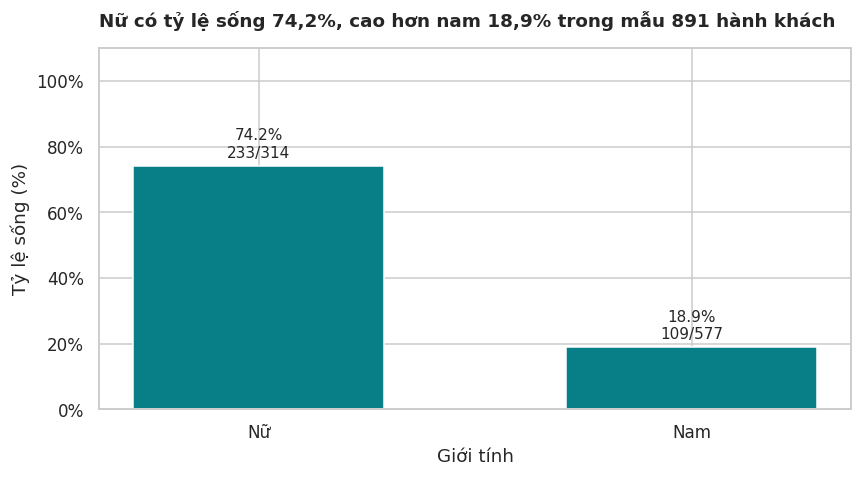

,pclass,n,alive,rate,pct
0,1,216,136,0.629630,62.962963
1,2,184,87,0.472826,47.282609
2,3,491,119,0.242363,24.236253


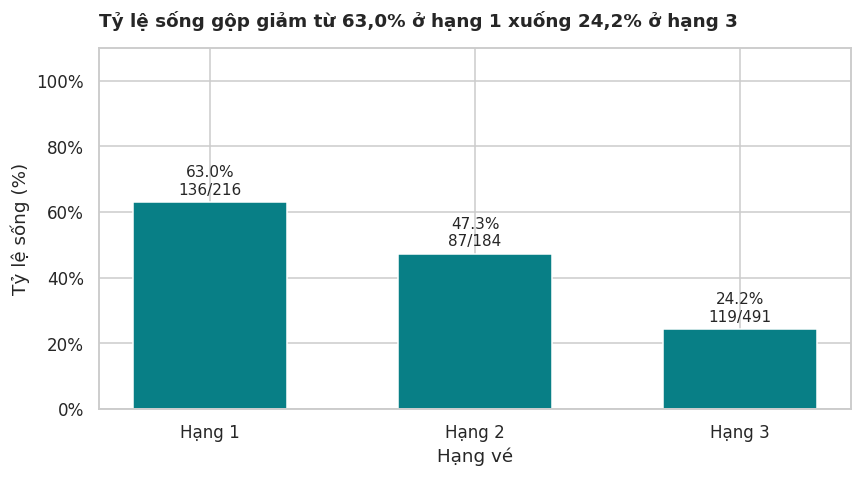

In [5]:
sex_stats = rate_bars(df, 'sex', {'female':'Nữ', 'male':'Nam'}, 'Giới tính',
    'Nữ có tỷ lệ sống 74,2%, cao hơn nam 18,9% trong mẫu 891 hành khách', '01_sex.png')
class_stats = rate_bars(df, 'pclass', {1:'Hạng 1', 2:'Hạng 2', 3:'Hạng 3'}, 'Hạng vé',
    'Tỷ lệ sống gộp giảm từ 63,0% ở hạng 1 xuống 24,2% ở hạng 3', '02_class.png')

Nữ: 233/314 (74,2%); nam: 109/577 (18,9%). Hạng 1: 136/216 (63,0%), hạng 2: 87/184 (47,3%), hạng 3: 119/491 (24,2%). Kết quả cho thấy chênh lệch trong mẫu, chưa xác nhận nguyên nhân hoặc quy trình sơ tán. Câu 3 sẽ so sánh hạng vé trong từng giới.

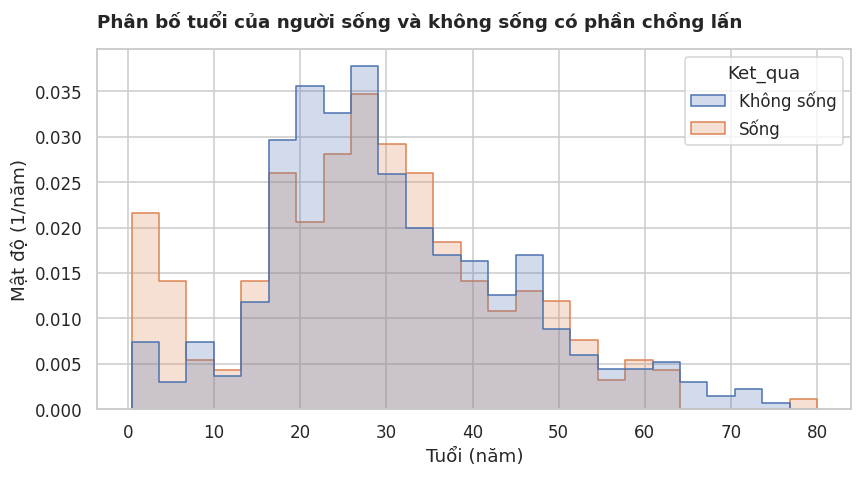

,family_size,n,alive,rate,pct
0,1,537,163,0.303538,30.353818
1,2,161,89,0.552795,55.279503
2,3,102,59,0.578431,57.843137
3,4,29,21,0.724138,72.413793
4,5,15,3,0.200000,20.000000
5,6,22,3,0.136364,13.636364
6,7,12,4,0.333333,33.333333
7,8,6,0,0.000000,0.000000
8,11,7,0,0.000000,0.000000


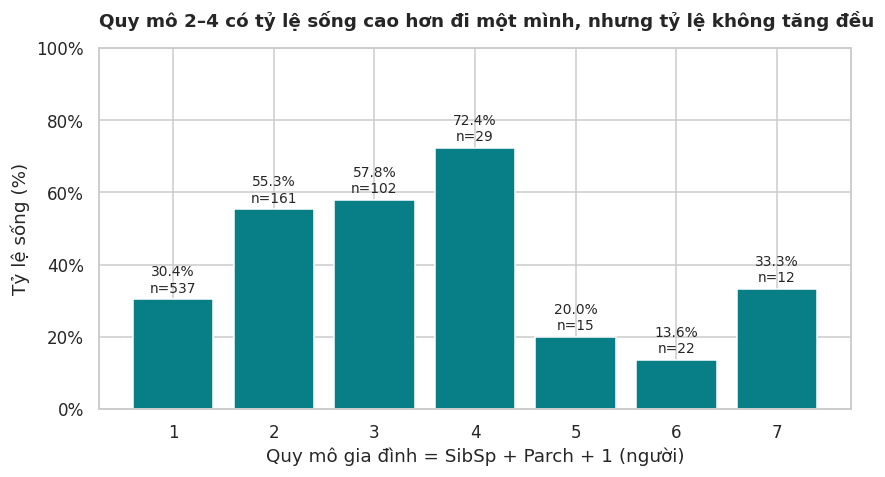

Nhóm n<10 chỉ không vẽ; không xóa khỏi dữ liệu: [8, 11]


In [6]:
age_plot = known.assign(Ket_qua=known.survived.map({0:'Không sống', 1:'Sống'}))
fig, ax = plt.subplots()
sns.histplot(data=age_plot, x='age', hue='Ket_qua', bins=25, stat='density', common_norm=False, element='step', ax=ax)
ax.set(xlabel='Tuổi (năm)', ylabel='Mật độ (1/năm)')
finish(fig, ax, 'Phân bố tuổi của người sống và không sống có phần chồng lấn', '03_age.png')
family_stats = summary(df, 'family_size')
display(family_stats)
plot_family = family_stats[family_stats.n >= 10]
fig, ax = plt.subplots()
bars = ax.bar(plot_family.family_size.astype(int).astype(str), plot_family.rate, color='#087F86')
for bar, row in zip(bars, plot_family.itertuples()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.02, f'{row.pct:.1f}%\nn={row.n}', ha='center', fontsize=9)
ax.set(xlabel='Quy mô gia đình = SibSp + Parch + 1 (người)', ylabel='Tỷ lệ sống (%)', ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
finish(fig, ax, 'Quy mô 2–4 có tỷ lệ sống cao hơn đi một mình, nhưng tỷ lệ không tăng đều', '04_family.png')
print('Nhóm n<10 chỉ không vẽ; không xóa khỏi dữ liệu:', family_stats[family_stats.n < 10].family_size.tolist())

Histogram hai nhóm chồng lấn nên tuổi không tách hoàn toàn kết quả sống. Đi một mình có tỷ lệ 30,4%, quy mô 2–4 lần lượt 55,3%, 57,8%, 72,4%; quy mô 5 chỉ 20,0%. Không suy ra gia đình 4 người là tối ưu: các nhóm khác nhau về giới, hạng vé và số quan sát.

,n,median
pclass,,
1,216,60.2875
2,184,14.2500
3,491,8.0500


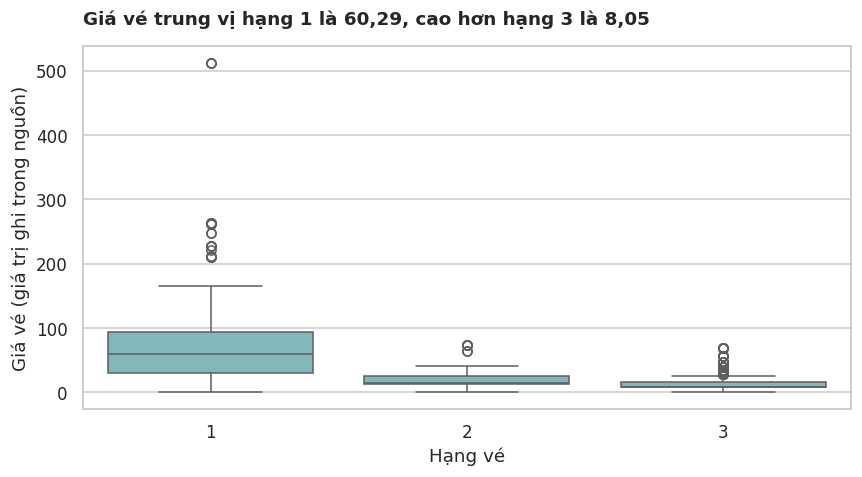

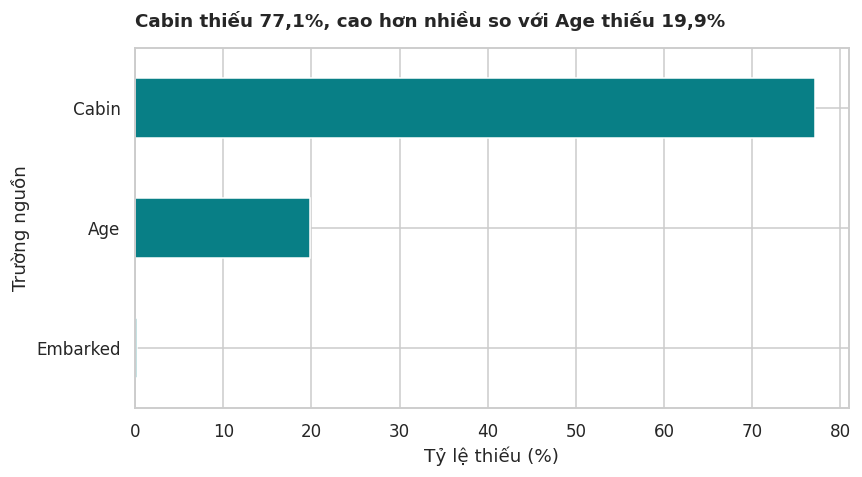

In [7]:
display(df.groupby('pclass', observed=True).fare.agg(n='count', median='median'))
fig, ax = plt.subplots()
sns.boxplot(data=df, x='pclass', y='fare', order=[1,2,3], showfliers=True, color='#78BFC2', ax=ax)
ax.set(xlabel='Hạng vé', ylabel='Giá vé (giá trị ghi trong nguồn)')
finish(fig, ax, 'Giá vé trung vị hạng 1 là 60,29, cao hơn hạng 3 là 8,05', '05_fare.png')
fig, ax = plt.subplots()
missing_pct = 100*raw.isna().mean()
missing_pct[missing_pct > 0].sort_values().plot.barh(ax=ax, color='#087F86')
ax.set(xlabel='Tỷ lệ thiếu (%)', ylabel='Trường nguồn')
finish(fig, ax, 'Cabin thiếu 77,1%, cao hơn nhiều so với Age thiếu 19,9%', '06_missing.png')

Giá vé có phân phối lệch phải và nhiều quan sát cao. IQR gắn cờ 116 dòng, ngưỡng trên 65,6344; giữ tất cả vì giá cao chưa đủ chứng minh sai. Có 15 dòng Fare=0 và không có Fare thiếu. Không đổi các số 0 thành NaN. Biểu đồ thể hiện các điểm ngoại lai, không cắt bỏ dữ liệu.

### Câu 2 Giả thuyết phụ nữ và trẻ em trước
So sánh tuổi gộp rồi tách theo giới để tránh diễn giải quá mức từ một biểu đồ.

,child,n,alive,rate,pct
0,>12 tuổi,645,250,0.387597,38.759690
1,≤12 tuổi,69,40,0.579710,57.971014


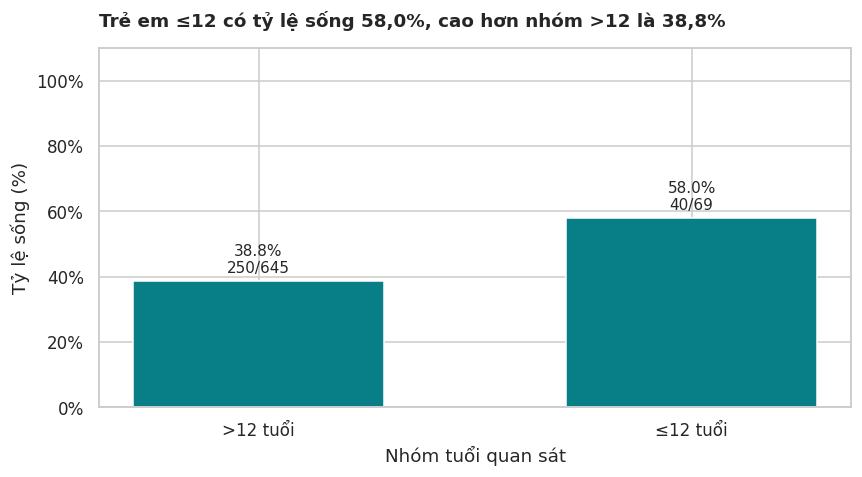

,sex,child,n,alive,rate,pct
0,female,>12 tuổi,229,178,0.777293,77.729258
1,female,≤12 tuổi,32,19,0.593750,59.375000
2,male,>12 tuổi,416,72,0.173077,17.307692
3,male,≤12 tuổi,37,21,0.567568,56.756757


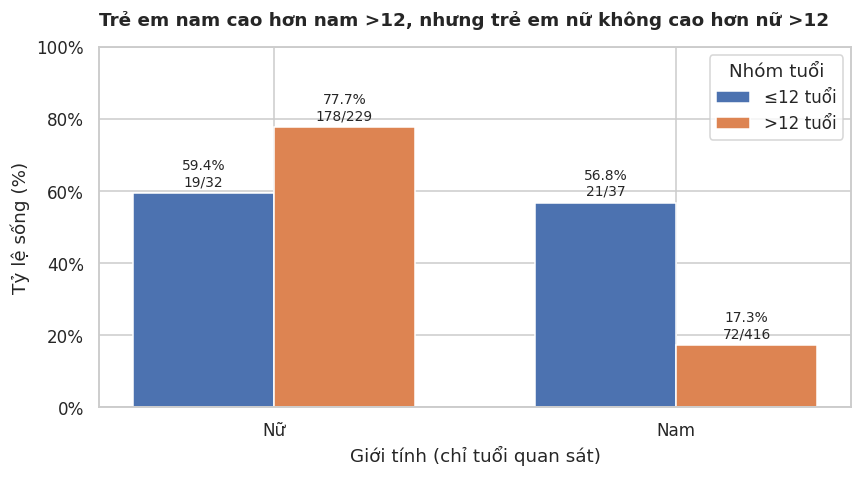

In [8]:
child_stats = rate_bars(known, 'child', {}, 'Nhóm tuổi quan sát',
    'Trẻ em ≤12 có tỷ lệ sống 58,0%, cao hơn nhóm >12 là 38,8%', '09_child.png')
sex_child = summary(known, ['sex','child'])
display(sex_child)
fig, ax = plt.subplots()
x = np.arange(2)
for j, label in enumerate(['≤12 tuổi', '>12 tuổi']):
    part = sex_child[sex_child.child == label].set_index('sex').loc[['female','male']]
    bars = ax.bar(x+(j-.5)*.35, part.rate, width=.35, label=label)
    for bar, row in zip(bars, part.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.02, f'{row.pct:.1f}%\n{row.alive}/{row.n}', ha='center', fontsize=9)
ax.set_xticks(x,['Nữ','Nam']); ax.set(xlabel='Giới tính (chỉ tuổi quan sát)',ylabel='Tỷ lệ sống (%)',ylim=(0,1))
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(title='Nhóm tuổi')
finish(fig, ax, 'Trẻ em nam cao hơn nam >12, nhưng trẻ em nữ không cao hơn nữ >12', '08_sex_child.png')

Trẻ em có 40/69 sống (58,0%), nhóm >12 là 250/645 (38,8%). Trong nam: 21/37 (56,8%) so với 72/416 (17,3%). Trong nữ: 19/32 (59,4%) so với 178/229 (77,7%). Giả thuyết có hỗ trợ mô tả khi nhìn nữ/nam và tuổi gộp, nhưng không đồng hướng ở mọi nhóm. Không có dữ liệu trình tự sơ tán để chứng minh “ưu tiên trước”.

### Câu 3 Bảng chéo giới tính × hạng vé
Đọc theo hàng để so sánh hạng vé trong cùng giới. Bảng dùng toàn bộ 891 hồ sơ, không giới hạn vào người có tuổi.

,sex,pclass,n,alive,rate,pct
0,female,1,94,91,0.968085,96.808511
1,female,2,76,70,0.921053,92.105263
2,female,3,144,72,0.500000,50.000000
3,male,1,122,45,0.368852,36.885246
4,male,2,108,17,0.157407,15.740741
5,male,3,347,47,0.135447,13.544669


pclass,1,2,3
sex,,,
female,96.808511,92.105263,50.000000
male,36.885246,15.740741,13.544669


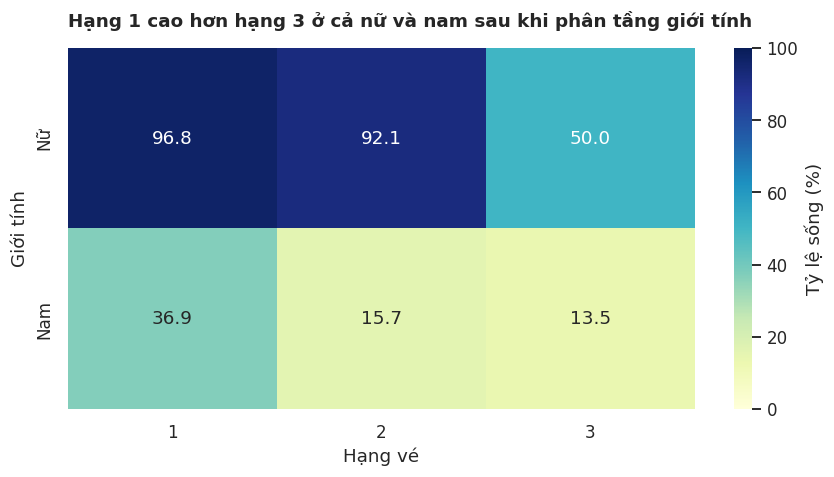

In [9]:
cross_stats = summary(df, ['sex','pclass'])
display(cross_stats)
cross_pct = pd.crosstab(df.sex, df.pclass, values=df.survived, aggfunc='mean')*100
display(cross_pct)
fig, ax = plt.subplots()
sns.heatmap(cross_pct.rename(index={'female':'Nữ','male':'Nam'}), annot=True, fmt='.1f',
    cmap='YlGnBu',vmin=0,vmax=100,cbar_kws={'label':'Tỷ lệ sống (%)'},ax=ax)
ax.set(xlabel='Hạng vé',ylabel='Giới tính')
finish(fig, ax, 'Hạng 1 cao hơn hạng 3 ở cả nữ và nam sau khi phân tầng giới tính', '07_sex_class.png')

Nữ hạng 1/2/3: 91/94 (96,8%), 70/76 (92,1%), 72/144 (50,0%). Nam: 45/122 (36,9%), 17/108 (15,7%), 47/347 (13,5%). Liên hệ hạng vé vẫn còn trong từng giới, không chỉ là chênh lệch giới tính của mẫu gộp. Tuy nhiên, đây chưa phải bằng chứng tác động nhân quả độc lập hoặc cơ chế trung gian. Cần giả thuyết nhân quả và xử lý các yếu tố gây nhiễu nếu muốn trả lời theo nghĩa đó; A2 không thực hiện suy luận này.

In [10]:
composition = df[df.family_size.isin([1,4,5])].groupby('family_size', observed=True).agg(
    n=('survived','size'), alive=('survived','sum'),
    female_pct=('sex',lambda s:s.eq('female').mean()*100),
    class3_pct=('pclass',lambda s:s.eq(3).mean()*100))
display(composition)
print('Cơ cấu nhóm khác nhau là một gợi ý diễn giải, chưa xác định nguyên nhân của chênh lệch.')

,n,alive,female_pct,class3_pct
family_size,,,,
1,537,163,23.463687,60.335196
4,29,21,65.517241,31.034483
5,15,3,80.000000,80.000000


Cơ cấu nhóm khác nhau là một gợi ý diễn giải, chưa xác định nguyên nhân của chênh lệch.


## 6. Ba câu trả lời và giới hạn tương ứng

**Câu 1:** giới tính, hạng vé, tuổi và quy mô gia đình có liên hệ mô tả với sống sót. Bằng chứng: nữ 74,2% so với nam 18,9%; hạng 1 là 63,0% so với hạng 3 là 24,2%; gia đình 2–4 là 55,3%–72,4% so với đi một mình 30,4%. Chưa xếp hạng tác động độc lập, không suy ra thay đổi một biến sẽ làm tăng cơ hội sống.

**Câu 2:** giả thuyết được hỗ trợ một phần. Trẻ em gộp 58,0% so với >12 là 38,8%; trẻ em nam 56,8% >17,3%, nhưng trẻ em nữ 59,4% <77,7%. Tuổi thiếu 177/891 và tỷ lệ sống không cho biết thứ tự cứu hộ.

**Câu 3:** hạng vé còn liên hệ sau phân tầng giới tính: nữ hạng 1/3 là 96,8%/50,0%, nam là 36,9%/13,5%. Chưa đủ xác nhận tác động nhân quả độc lập, độc lập thống kê toàn phần hoặc vai trò biến trung gian.

## 7. Giới hạn và cách sử dụng kết quả

Mẫu 891 hồ sơ có nhãn không phải toàn bộ hành khách Titanic; không mô tả thủy thủ đoàn. Không suy rộng trực tiếp cho tàu khác hoặc bối cảnh hiện đại. Các thành viên cùng gia đình có thể phụ thuộc nhau; quy mô gia đình không phải số gia đình độc lập. Tỷ lệ nhóm nhỏ dễ dao động.

Tuổi thiếu 19,9%; mẫu biết tuổi có thể khác phần thiếu. Điền trung vị giảm độ phân tán nhưng không khôi phục tuổi thật. Giới và hạng vé không đo đầy đủ quy trình sơ tán, vị trí trên tàu hoặc điều kiện kinh tế. Dữ liệu quan sát không xác định nguyên nhân và không chứng minh ưu tiên cứu hộ. Bỏ trường định danh khỏi bảng phân tích không bảo đảm ẩn danh tuyệt đối; không trình bày hồ sơ cá nhân.

Không áp dụng tỷ lệ nhóm để dán nhãn hoặc giảm cơ hội của cá nhân hiện tại. Theo đề A2-02, Titanic xếp tầng Cơ bản, có ngoại lệ dưới 2.000 dòng và điểm trần 8,0. Không tạo ngày giả để đáp ứng điều kiện chung.

In [11]:
assert raw.shape == (891,12) and df.shape == (891,10)
assert clean.passengerid.is_unique and clean.passengerid.notna().all()
assert df.survived.isin([0,1]).all() and int(df.survived.sum()) == 342
assert df.pclass.isin([1,2,3]).all() and df.sex.isin(['female','male']).all()
assert df[['sibsp','parch']].notna().all().all()
assert (df[['sibsp','parch']] >= 0).all().all()
assert (df.age.dropna() > 0).all() and (df.fare.dropna() >= 0).all()
assert df.age.isna().sum() == 177 and df.fare.isna().sum() == 0
assert len(known) == 714 and known.survived.sum() == 290
assert duplicates == 0 and sum(coercions.values()) == 0
assert cross_stats.n.sum() == 891 and cross_stats.alive.sum() == 342
assert sex_child.n.sum() == 714 and sex_child.alive.sum() == 290
assert age_b.notna().all() and age_c.notna().all()
assert hashlib.sha256(DATA_FILE.read_bytes()).hexdigest() == '4a437fde05fe5264e1701a7387ac6fb75393772ba38bb2c9c566405af5af4bd7'
print('14 nhóm assert đạt: dữ liệu, miền giá trị, mẫu số, tổng sống và toàn vẹn CSV.')

14 nhóm assert đạt: dữ liệu, miền giá trị, mẫu số, tổng sống và toàn vẹn CSV.


## 8. Công cụ, phân công và tài liệu

Duy (240464), 60%: tổ chức notebook, làm sạch, câu 1 và câu 3, tổng hợp báo cáo. Bảo (240233), 40%: đối chiếu nguồn, câu 2, kiểm tra nhãn/mẫu số và chuẩn bị hỏi đáp. Cả hai cần tự chạy lại và hiểu toàn bộ bài.

Công cụ: Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter/Colab. OpenAI Codex hỗ trợ mã, bản thảo và kiểm tra kỹ thuật. Không khai báo thành viên đã tự kiểm chứng nếu chưa làm.

- [Đề A2-02](https://lms.tbd.edu.vn/mod/page/view.php?id=153568)
- [Yêu cầu Buổi 11](https://lms.tbd.edu.vn/mod/assign/view.php?id=132833)
- [Kaggle Titanic và dữ liệu](https://www.kaggle.com/competitions/titanic/data)
- [Quy tắc Kaggle](https://www.kaggle.com/competitions/titanic/rules)
- [Pandas read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [Pandas crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html)
- [Pandas cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html)
- Repo nhóm: https://github.com/hoangduydz/CNTT219-LuongCongHoangDuy